<a href="https://colab.research.google.com/github/LalTamatar/Hackathon-file/blob/main/CIFAR_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

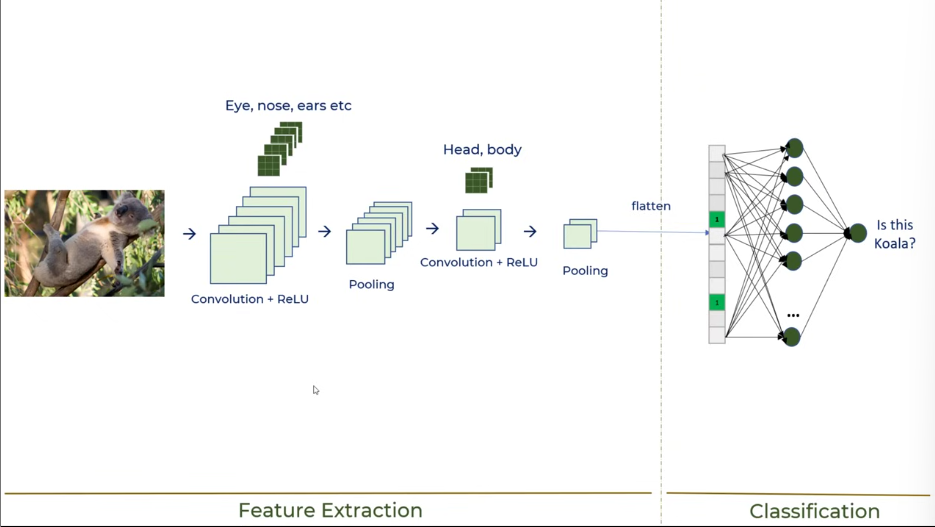

So basically what we are doing is, we are taking the image pixel by pixel, then doing convolution on it, so as to easily determine the specific feature 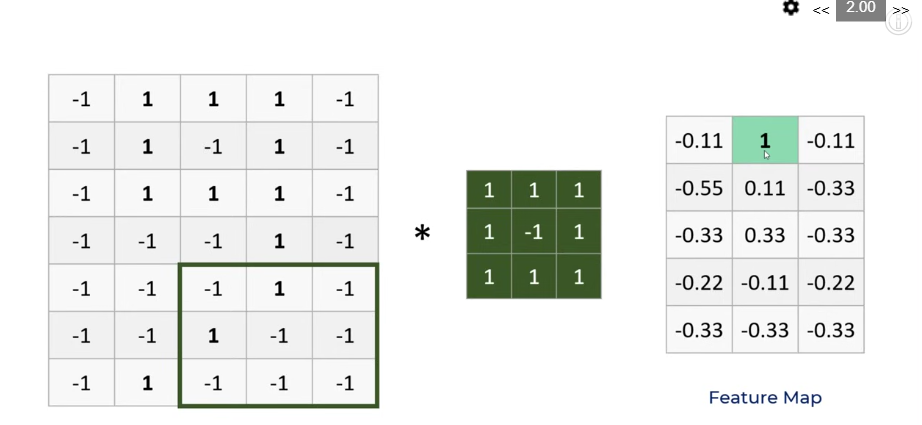

We do pooling as to minimze the no. of inputs for less computation.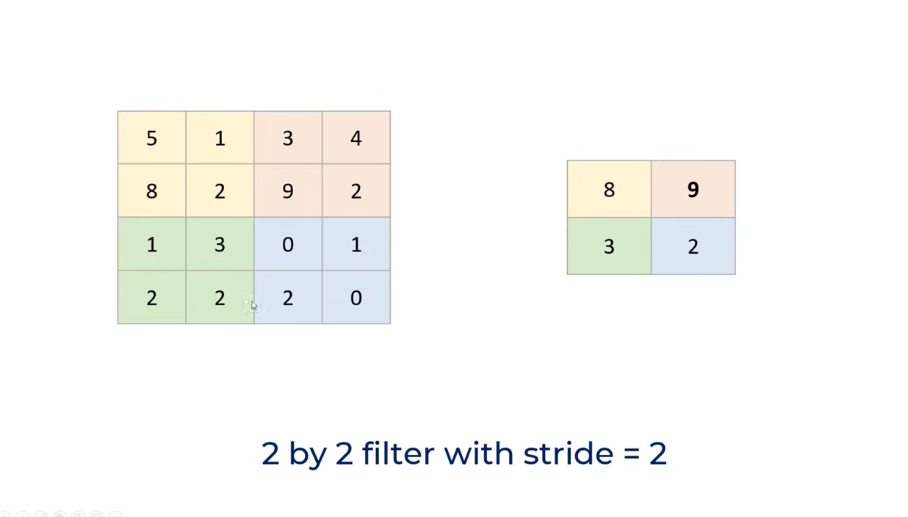

and after that we just flatten it into neuron and go on

In [5]:
import tensorflow as tf
from keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

In [6]:
(X_train, Y_train), (X_test, Y_test) = datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1586s 9us/step


In [7]:
X_train.shape, Y_train.shape


((50000, 32, 32, 3), (50000, 1))

In [8]:
X_test.shape, Y_test.shape

((10000, 32, 32, 3), (10000, 1))

array([[[ 59,  62,  63],
        [ 43,  46,  45],
        [ 50,  48,  43],
        ...,
        [158, 132, 108],
        [152, 125, 102],
        [148, 124, 103]],

       [[ 16,  20,  20],
        [  0,   0,   0],
        [ 18,   8,   0],
        ...,
        [123,  88,  55],
        [119,  83,  50],
        [122,  87,  57]],

       [[ 25,  24,  21],
        [ 16,   7,   0],
        [ 49,  27,   8],
        ...,
        [118,  84,  50],
        [120,  84,  50],
        [109,  73,  42]],

       ...,

       [[208, 170,  96],
        [201, 153,  34],
        [198, 161,  26],
        ...,
        [160, 133,  70],
        [ 56,  31,   7],
        [ 53,  34,  20]],

       [[180, 139,  96],
        [173, 123,  42],
        [186, 144,  30],
        ...,
        [184, 148,  94],
        [ 97,  62,  34],
        [ 83,  53,  34]],

       [[177, 144, 116],
        [168, 129,  94],
        [179, 142,  87],
        ...,
        [216, 184, 140],
        [151, 118,  84],
        [123,  92,  72]]], dtype=uint8)
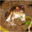

In [9]:
X_train[0]

In [10]:
Y_train[:5]

array([[6],
       [9],
       [9],
       [4],
       [1]], dtype=uint8)

In [11]:
Y_train = Y_train.reshape(-1,)
Y_train[:5] #transforming it into 1d array

array([6, 9, 9, 4, 1], dtype=uint8)

In [12]:
classes =["airplane", "automobile", "bird", "cat", "deer","dog", "frog", "horse", "ship", "truck"]

In [13]:
def plot_sample(X, Y, index):
  plt.figure(figsize=(15, 2))
  plt.imshow(X[index])
  plt.xlabel(classes[Y[index]])

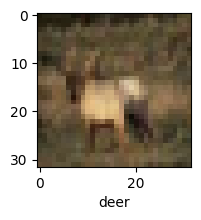

In [14]:
plot_sample(X_train, Y_train, 3);

In [15]:
X_train = X_train/255
X_test = X_test/255 #to do it for between 0 and 1

In [16]:
ann = models.Sequential([
    layers.Flatten(input_shape = (32, 32, 3)),
    layers.Dense(3000, activation='relu'),
    layers.Dense(3000, activation='relu'),
    layers.Dense(10, activation='sigmoid') #sigmoid smashes the function between 0 and 1
])

ann.compile(optimizer='adam',
            loss = 'sparse_categorical_crossentropy',
            metrics=['accuracy'])




/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [17]:
from keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(monitor = 'val_loss',
                               patience =8,
                               restore_best_weights=True)

ann.fit(X_train, Y_train, epochs =100, batch_size=256, validation_data=(X_test, Y_test), callbacks=[early_stopping])

Epoch 1/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.3039 - loss: 2.1592 - val_accuracy: 0.3390 - val_loss: 1.8463
Epoch 2/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.4021 - loss: 1.6691 - val_accuracy: 0.4192 - val_loss: 1.6577
Epoch 3/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.4362 - loss: 1.5803 - val_accuracy: 0.4389 - val_loss: 1.5701
Epoch 4/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.4577 - loss: 1.5168 - val_accuracy: 0.4610 - val_loss: 1.5132
Epoch 5/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.4755 - loss: 1.4736 - val_accuracy: 0.4687 - val_loss: 1.4876
Epoch 6/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.4860 - loss: 1.4423 - val_accuracy: 0.4723 - val_loss: 1.4672
Epoch 7/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.4992 - loss: 1.4023 - val_accuracy: 0.4863 - val_loss: 1.4355
Epoch 8/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5075 - loss: 1.3836 - 

In [18]:
#classification report
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
y_pred = ann.predict(X_test)
y_pred_classes = [np.argmax(element) for element in y_pred]

print("Classification Report: \n", classification_report(Y_test, y_pred_classes))

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
Classification Report: 
               precision    recall  f1-score   support

           0       0.63      0.56      0.60      1000
           1       0.60      0.61      0.61      1000
           2       0.42      0.40      0.41      1000
           3       0.44      0.29      0.35      1000
           4       0.48      0.43      0.45      1000
           5       0.46      0.41      0.44      1000
           6       0.52      0.62      0.57      1000
           7       0.54      0.63      0.58      1000
           8       0.58      0.73      0.65      1000
           9       0.53      0.56      0.55      1000

    accuracy                           0.53     10000
   macro avg       0.52      0.53      0.52     10000
weighted avg       0.52      0.53      0.52     10000



In [19]:
cnn= models.Sequential([
    #cnn
    layers.Conv2D(filters=32, activation='relu', kernel_size=(3,3), input_shape=(32,32, 3)),#There will be 32 filters on which it will be judged, it will automatically make them, the filter size or kernel size, we take 3,3, activation is relu and input shape is 32,32,3
    layers.MaxPooling2D((2,2)), #used to take the max in a given 2x2 grid so as to shorten the time

    layers.Conv2D(filters =64, kernel_size=(3,3), activation ='relu'),
    layers.MaxPooling2D((2,2)),

    #dense
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [21]:
cnn.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [22]:
early = EarlyStopping(
    monitor='val_loss',
    patience = 8,
    restore_best_weights=True
)

cnn.fit(X_train, Y_train, batch_size=256, epochs =100, callbacks=[early], validation_data=(X_test, Y_test))

Epoch 1/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.3852 - loss: 1.7126 - val_accuracy: 0.4703 - val_loss: 1.5037
Epoch 2/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.5196 - loss: 1.3620 - val_accuracy: 0.5299 - val_loss: 1.3095
Epoch 3/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.5687 - loss: 1.2349 - val_accuracy: 0.5847 - val_loss: 1.1871
Epoch 4/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.5999 - loss: 1.1509 - val_accuracy: 0.6026 - val_loss: 1.1354
Epoch 5/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6221 - loss: 1.0865 - val_accuracy: 0.6227 - val_loss: 1.0764
Epoch 6/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6396 - loss: 1.0372 - val_accuracy: 0.6371 - val_loss: 1.0407
Epoch 7/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6560 - loss: 0.9946 - val_accuracy: 0.6537 - val_loss: 1.0052
Epoch 8/100
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6680 - loss: 0.9594 - val_ac

In [23]:
cnn.evaluate(X_test, Y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6997 - loss: 0.8941


[0.8941173553466797, 0.6996999979019165]

In [25]:
Y_test= Y_test.reshape(-1,)
Y_test[:5]

array([3, 8, 8, 0, 6], dtype=uint8)

In [26]:
y_pred = cnn.predict(X_test)
y_pred[:5]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


array([[4.3308353e-03, 4.4058706e-05, 5.9440811e-03, 8.4735435e-01,
        1.3360122e-03, 9.1717228e-02, 4.4249777e-02, 1.8235025e-04,
        4.6621803e-03, 1.7932520e-04],
       [1.2220148e-01, 4.4345033e-01, 1.7961251e-05, 1.6204147e-06,
        4.9525024e-05, 1.6656026e-08, 9.4116507e-07, 8.2442773e-07,
        4.3356651e-01, 7.1074755e-04],
       [1.0395433e-01, 6.2564576e-01, 9.8498829e-04, 9.8308185e-03,
        9.4347284e-04, 3.6089742e-04, 3.2175501e-04, 1.7245093e-03,
        2.3896304e-01, 1.7270423e-02],
       [9.4257897e-01, 1.9591439e-03, 7.5342590e-03, 3.0947353e-03,
        2.5812676e-03, 7.7527875e-06, 7.8351592e-04, 5.5780587e-05,
        4.1378498e-02, 2.6100237e-05],
       [2.4562863e-05, 4.1695468e-05, 2.1699090e-02, 1.5377124e-02,
        2.2077911e-01, 3.0795929e-03, 7.3894340e-01, 7.0617557e-06,
        4.4577311e-05, 3.8940375e-06]], dtype=float32)

In [27]:
y_classes =[np.argmax(element) for element in y_pred]
y_classes[:5]

[np.int64(3), np.int64(1), np.int64(1), np.int64(0), np.int64(6)]

In [30]:
Y_test[:5]

array([3, 8, 8, 0, 6], dtype=uint8)

In [35]:
# 1. Connect your Google Drive to this session
from google.colab import drive
drive.mount('/content/drive')

# 2. Save the entire model to your Drive (.keras format is recommended)
cnn.save("/content/drive/MyDrive/CIFAR10_best_model.keras")
print("Model saved successfully to Google Drive!")


Mounted at /content/drive
Model saved successfully to Google Drive!


In [33]:
# This bypasses Google Drive completely
cnn.save("cifar10_best_model.keras")
print("Model saved to local Colab files!")


Model saved to local Colab files!
